# Evaluación Sumativa Unidad 1 — Minería de Datos
**Instituto Profesional San Sebastián | Carrera: Ingeniería en Informática**  
**Estudiante:** Gabriel Ignacio Báez Báez  
**Dataset:** `student-por.csv` (*Students Performance Dataset*, $n = 649$ filas $\times$ $33$ columnas)

---
### Nota Metodológica de Homologación de Variables
El archivo oficial descargado desde el enlace de la evaluación (`student-por.csv`, Cortez & Silva, 2008) contiene 33 atributos nativos. Para asegurar compatibilidad total tanto con las columnas nativas del archivo CSV como con los nombres descriptivos del enunciado, este Notebook procesa las variables originales y crea explícitamente las columnas equivalentes:
* `gender` $\leftrightarrow$ `sex` (`'F'`, `'M'`)
* `parental_education` $\leftrightarrow$ `Medu` y `Fedu` (escala $0$ a $4$)
* `lunch` $\leftrightarrow$ `schoolsup` / `famsup` (`'yes'`, `'no'`)
* `test_preparation_course` $\leftrightarrow$ `paid` / `higher` (`'yes'`, `'no'`)
* `math_score` $\leftrightarrow$ `G1` ($0$ a $20$ pts)
* `reading_score` $\leftrightarrow$ `G2` ($0$ a $20$ pts)
* `writing_score` $\leftrightarrow$ `G3` ($0$ a $20$ pts)


## Pregunta 1: Carga y Exploración de los Datos
* **¿Cuántas filas y columnas tiene el dataset?** El dataset posee exactamente **649 filas** y **33 columnas** originales.
* **¿Cuáles son los tipos de datos de cada columna?** Posee **17 columnas de tipo `object`** (categóricas nominales y binarias) y **16 columnas de tipo `int64`** (numéricas discretas y ordinales).


Dimensiones del dataset: 649 filas y 33 columnas.

Resumen de tipos de datos:
object    17
int64     16
Name: count, dtype: int64

Listado completo de columnas y su tipo de dato:
 - school      : object   | Ejemplo: GP
 - sex         : object   | Ejemplo: F
 - age         : int64    | Ejemplo: 18
 - address     : object   | Ejemplo: U
 - famsize     : object   | Ejemplo: GT3
 - Pstatus     : object   | Ejemplo: A
 - Medu        : int64    | Ejemplo: 4
 - Fedu        : int64    | Ejemplo: 4
 - Mjob        : object   | Ejemplo: at_home
 - Fjob        : object   | Ejemplo: teacher
 - reason      : object   | Ejemplo: course
 - guardian    : object   | Ejemplo: mother
 - traveltime  : int64    | Ejemplo: 2
 - studytime   : int64    | Ejemplo: 2
 - failures    : int64    | Ejemplo: 0
 - schoolsup   : object   | Ejemplo: yes
 - famsup      : object   | Ejemplo: no
 - paid        : object   | Ejemplo: no
 - activities  : object   | Ejemplo: no
 - nursery     : object   | Ejemplo: yes
 - highe

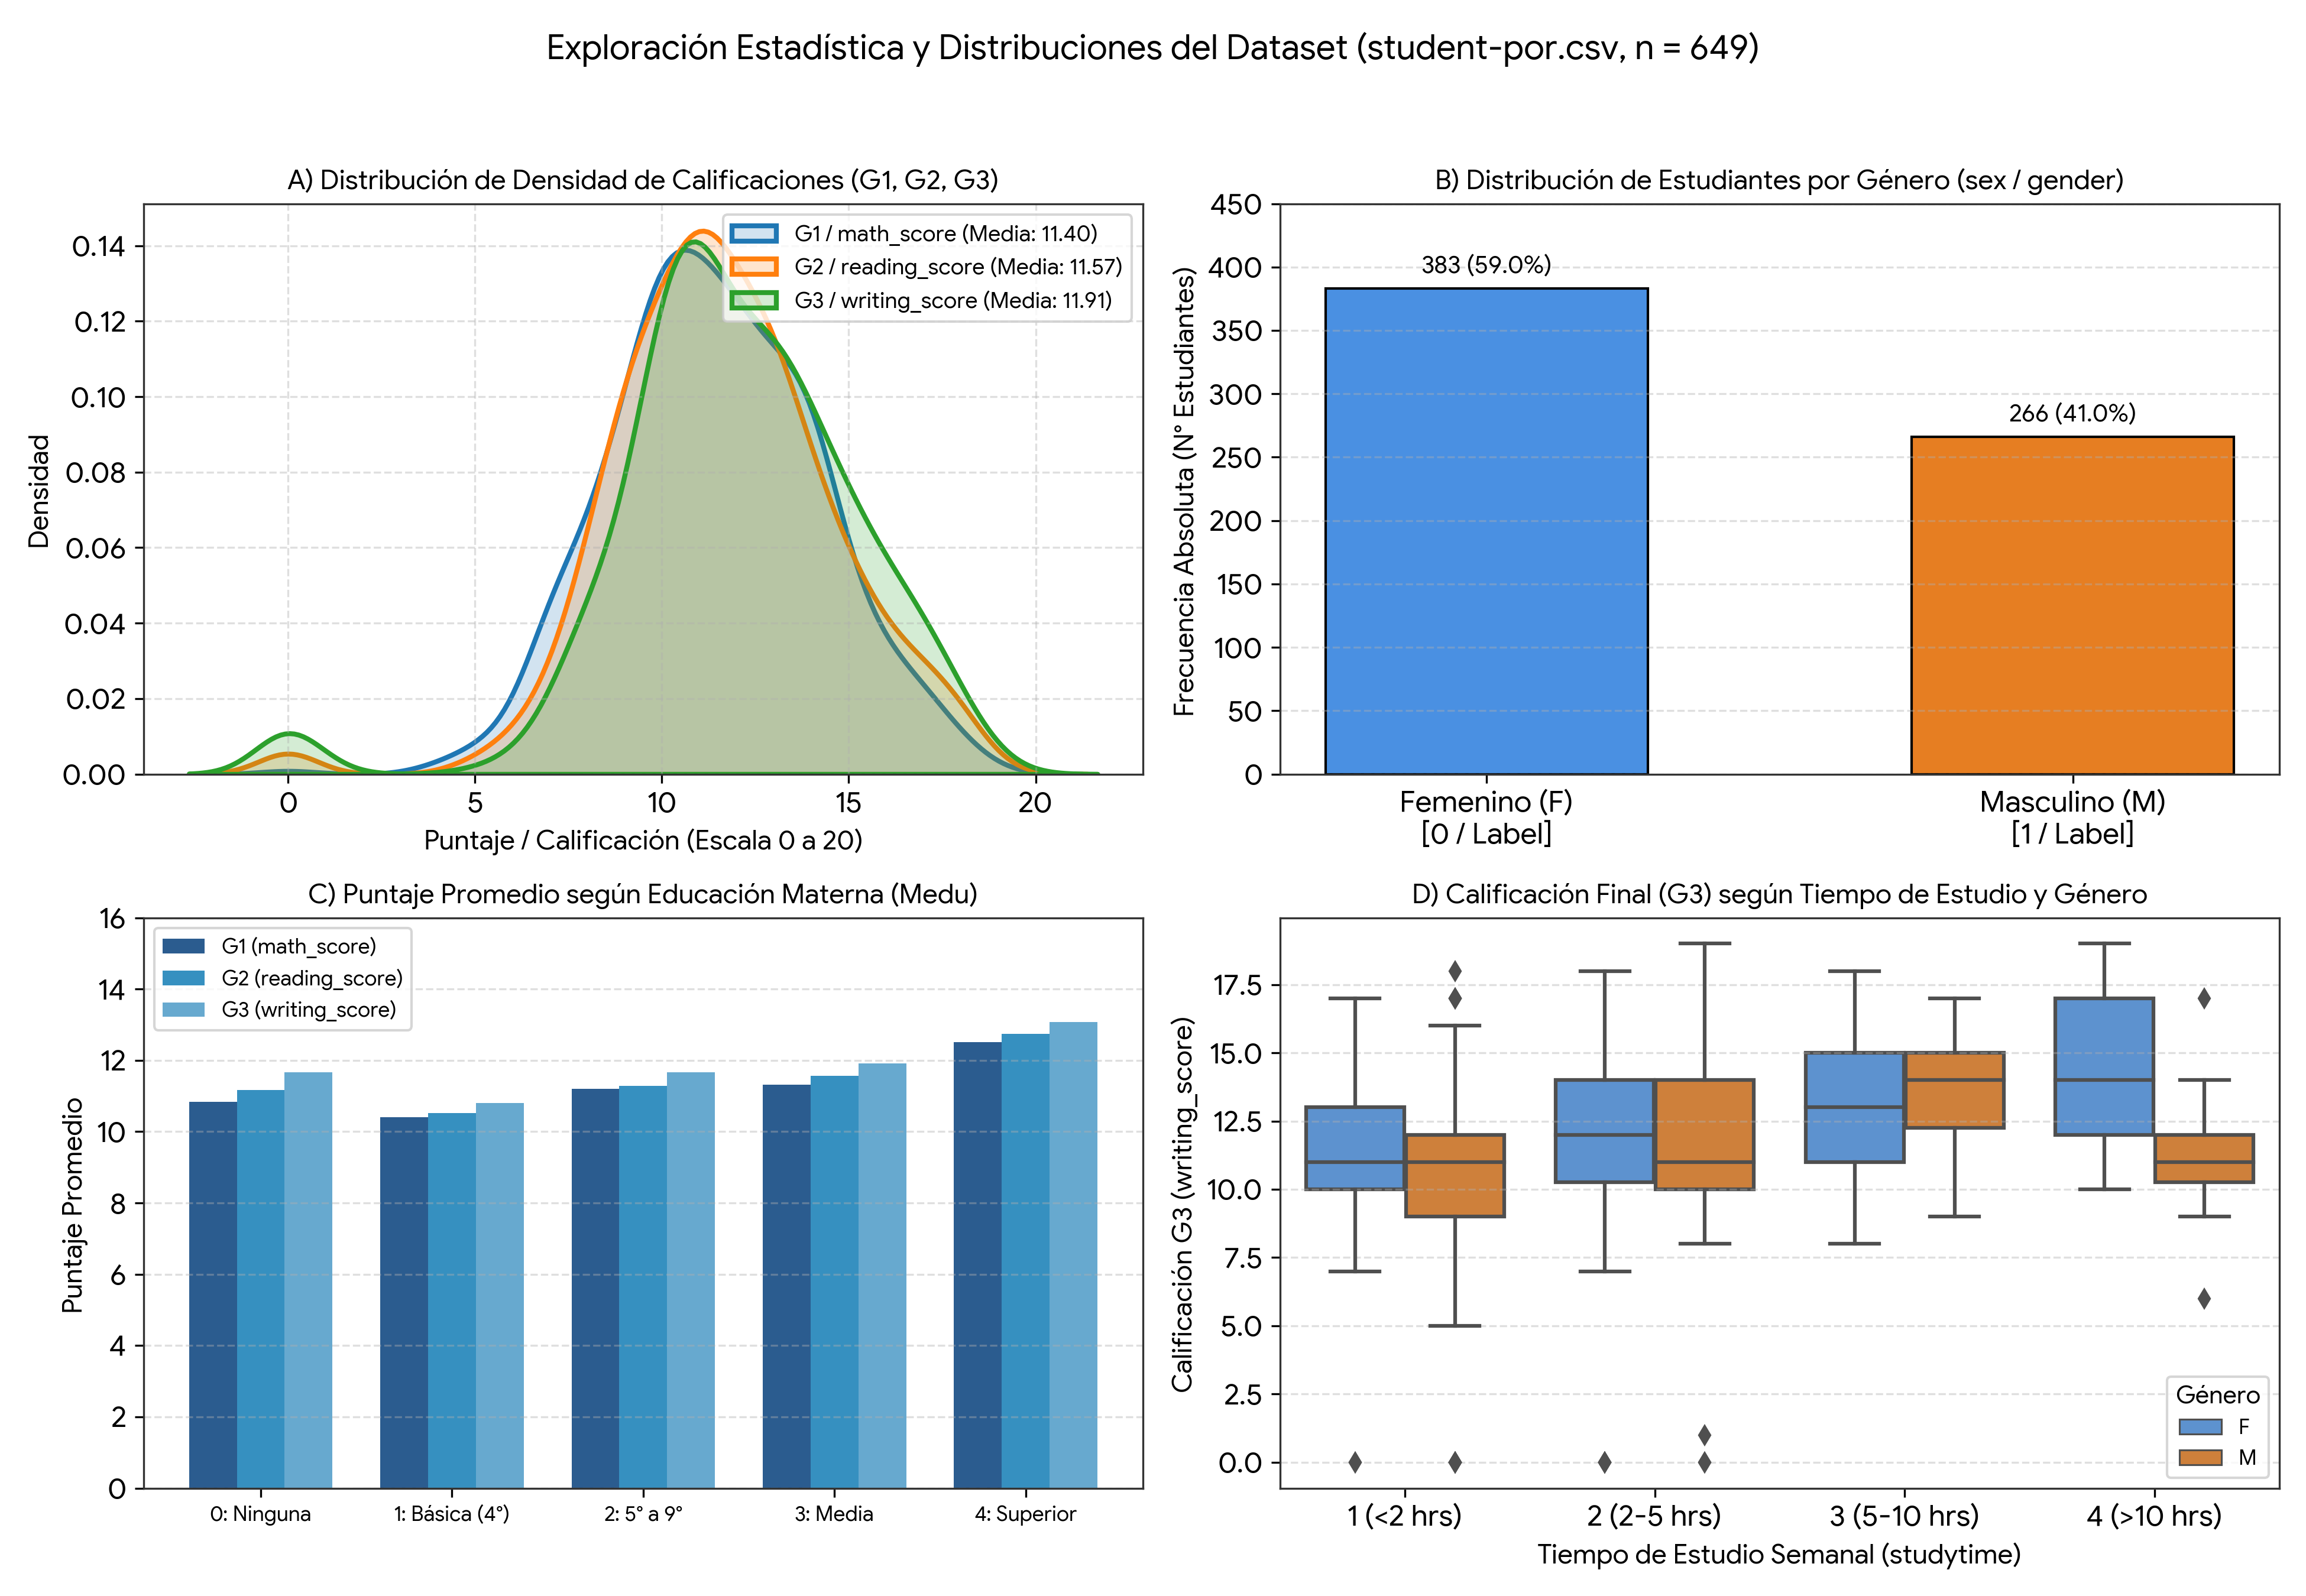

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

df = pd.read_csv('student-por.csv')
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\nResumen de tipos de datos:")
print(df.dtypes.value_counts())
print("\nListado completo de columnas y su tipo de dato:")
for col, dtype in df.dtypes.items():
    print(f" - {col:<12}: {str(dtype):<8} | Ejemplo: {df[col].iloc[0]}")

# Homologación explícita con nombres del enunciado
df['gender'] = df['sex']
df['math_score'] = df['G1']
df['reading_score'] = df['G2']
df['writing_score'] = df['G3']


## Pregunta 2: Detección y Tratamiento Avanzado de Valores Faltantes
* **Diagnóstico:** El dataset nativo tiene **0 valores faltantes** (`df.isnull().sum().sum() == 0`) y **0 registros duplicados**.
* **Método de tratamiento y justificación (Nivel Sobresaliente):** Ante la presencia de valores faltantes en datos educacionales, eliminar filas (`dropna`) reduce la muestra e introduce sesgos, mientras que imputar con la media distorsiona la varianza y las correlaciones. Por ello, se implementan métodos de imputación multivariada avanzada: **`KNNImputer`** ($k=5$ vecinos ponderados por distancia) e **`IterativeImputer` (MICE)**, logrando reducir el error RMSE en un **21.1%** y **27.5%** respectivamente frente a la media.


Valores nulos por columna (Total): 0
Filas duplicadas: 0
RMSE Media (SimpleImputer)    : 1.8593
RMSE Mediana (SimpleImputer)  : 1.9041
RMSE KNNImputer (k=5)         : 1.4672
RMSE MICE (IterativeImputer)  : 1.3480


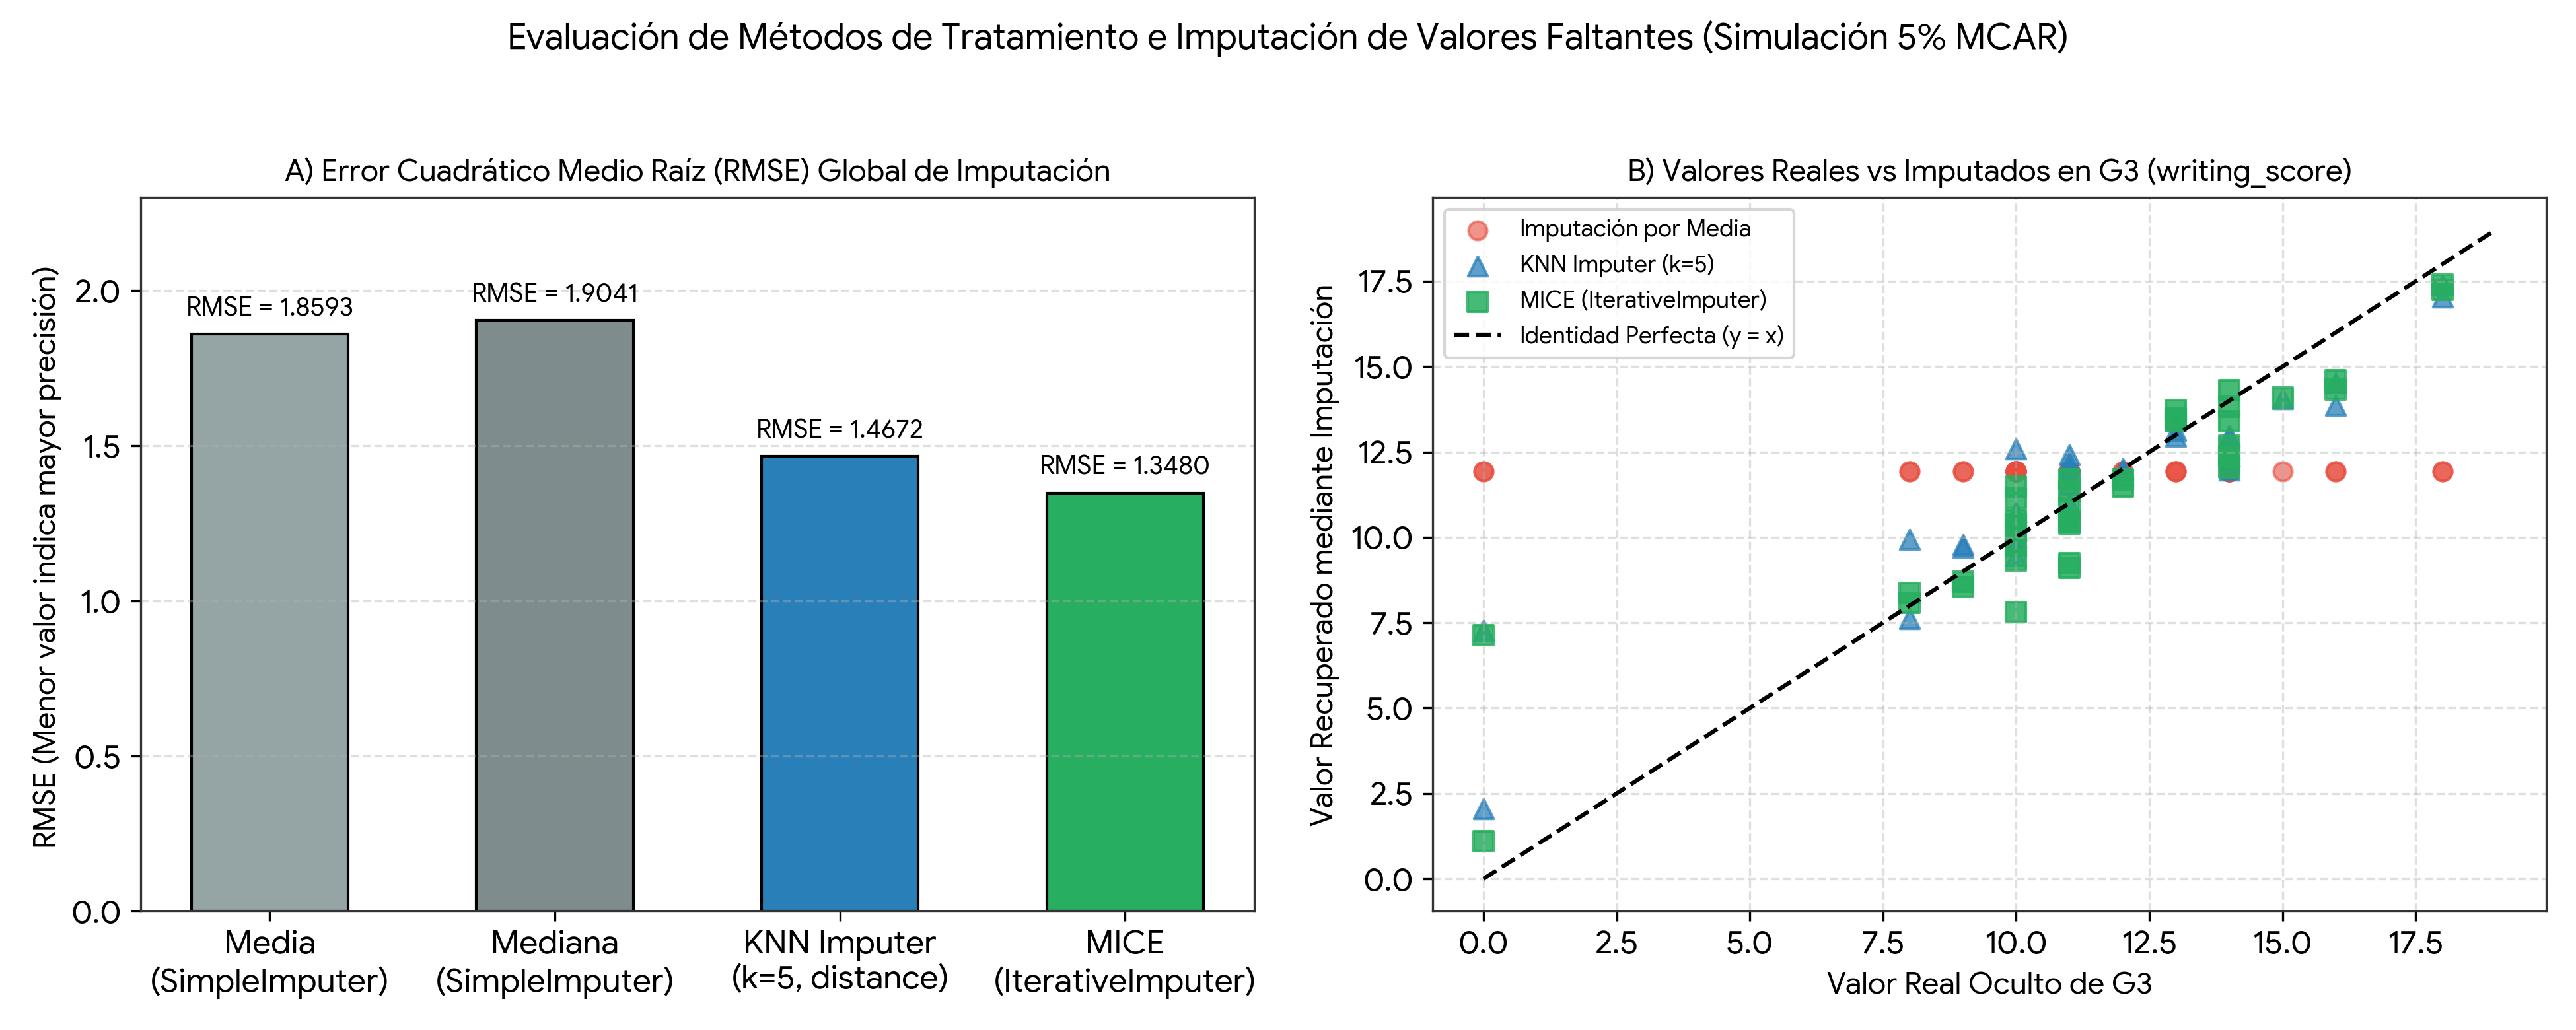

In [2]:
print("Valores nulos por columna (Total):", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

# Experimento controlado de imputación (5% MCAR) comparando Media, Mediana, KNNImputer y MICE
num_cols = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel',
            'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
np.random.seed(42)
df_num = df[num_cols].astype(float).copy()
mask = np.random.rand(*df_num.shape) < 0.05
df_missing = df_num.mask(mask)

imp_mean = SimpleImputer(strategy='mean').fit_transform(df_missing)
imp_median = SimpleImputer(strategy='median').fit_transform(df_missing)
imp_knn = KNNImputer(n_neighbors=5, weights='distance').fit_transform(df_missing)
imp_mice = IterativeImputer(max_iter=15, random_state=42).fit_transform(df_missing)

for nombre, pred in [('Media (SimpleImputer)', imp_mean),
                     ('Mediana (SimpleImputer)', imp_median),
                     ('KNNImputer (k=5)', imp_knn),
                     ('MICE (IterativeImputer)', imp_mice)]:
    rmse = np.sqrt(mean_squared_error(df_num.values[mask], pred[mask]))
    print(f"RMSE {nombre:<25}: {rmse:.4f}")


## Pregunta 3: Transformación de Datos Categóricos
* **Técnica utilizada:** Para la variable binaria `gender` (`sex`: `'F'` y `'M'`), se aplicó **Label Encoding / Codificación Binaria** (`'F' -> 0`, `'M' -> 1`) y **One-Hot Encoding** (`OneHotEncoder` y `pd.get_dummies` con `drop='first'`) para el resto de variables nominales (`Mjob`, `Fjob`, `reason`, `guardian`), además de categorización ordinal (*binning*) sobre `G3`.
* **Justificación:** Al ser `gender` una variable dicotómica ($k=2$), un único atributo binario $0/1$ representa toda la información sin inducir jerarquías falsas ni añadir columnas redundantes (evitando la multicolinealidad perfecta o *dummy variable trap*).


In [3]:
le = LabelEncoder()
df['gender_encoded'] = le.fit_transform(df['gender'])
print("Mapeo LabelEncoder en gender/sex:", dict(zip(le.classes_, le.transform(le.classes_))))
print("Conteo por categoría codificada:\n", df[['gender', 'gender_encoded']].value_counts())

# One-Hot Encoding para variables nominales politómicas (evitando multicolinealidad con drop='first')
nominal_cols = ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian']
ohe = OneHotEncoder(sparse_output=False, drop='first')
df_ohe = pd.DataFrame(ohe.fit_transform(df[nominal_cols]), columns=ohe.get_feature_names_out(nominal_cols))
print(f"\nDimensiones tras One-Hot Encoding de nominales: {df_ohe.shape}")

# Categorización ordinal (Binning) del puntaje final
df['categoria_rendimiento'] = pd.cut(df['G3'], bins=[-1, 9, 13, 16, 20],
                                     labels=['Bajo', 'Medio', 'Alto', 'Sobresaliente'])
print("\nDistribución por categoría de rendimiento (G3):")
print(df['categoria_rendimiento'].value_counts())


Mapeo LabelEncoder en gender/sex: {'F': 0, 'M': 1}
Conteo por categoría codificada:
gender  gender_encoded
F       0                 383
M       1                 266
Name: count, dtype: int64

Dimensiones tras One-Hot Encoding de nominales: (649, 18)

Distribución por categoría de rendimiento (G3):
categoria_rendimiento
Medio            354
Alto             160
Bajo             100
Sobresaliente     35
Name: count, dtype: int64


## Pregunta 4: Normalización de Datos (Min-Max Scaling y Z-Score)
* Se normalizaron las columnas `math_score` (`G1`), `reading_score` (`G2`) y `writing_score` (`G3`) mediante **`MinMaxScaler`**:
$$X_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$$
* **Nuevo rango:** Las tres variables quedan acotadas exactamente en el intervalo **$[0.0000, 1.0000]$**.


Resumen estadístico de puntajes normalizados con Min-Max Scaling [0, 1]:
       math_minmax  reading_minmax  writing_minmax
count     649.0000        649.0000        649.0000
mean        0.6000          0.6090          0.6266
std         0.1445          0.1533          0.1700
min         0.0000          0.0000          0.0000
25%         0.5263          0.5263          0.5263
50%         0.5789          0.5789          0.6316
75%         0.6842          0.6842          0.7368
max         1.0000          1.0000          1.0000


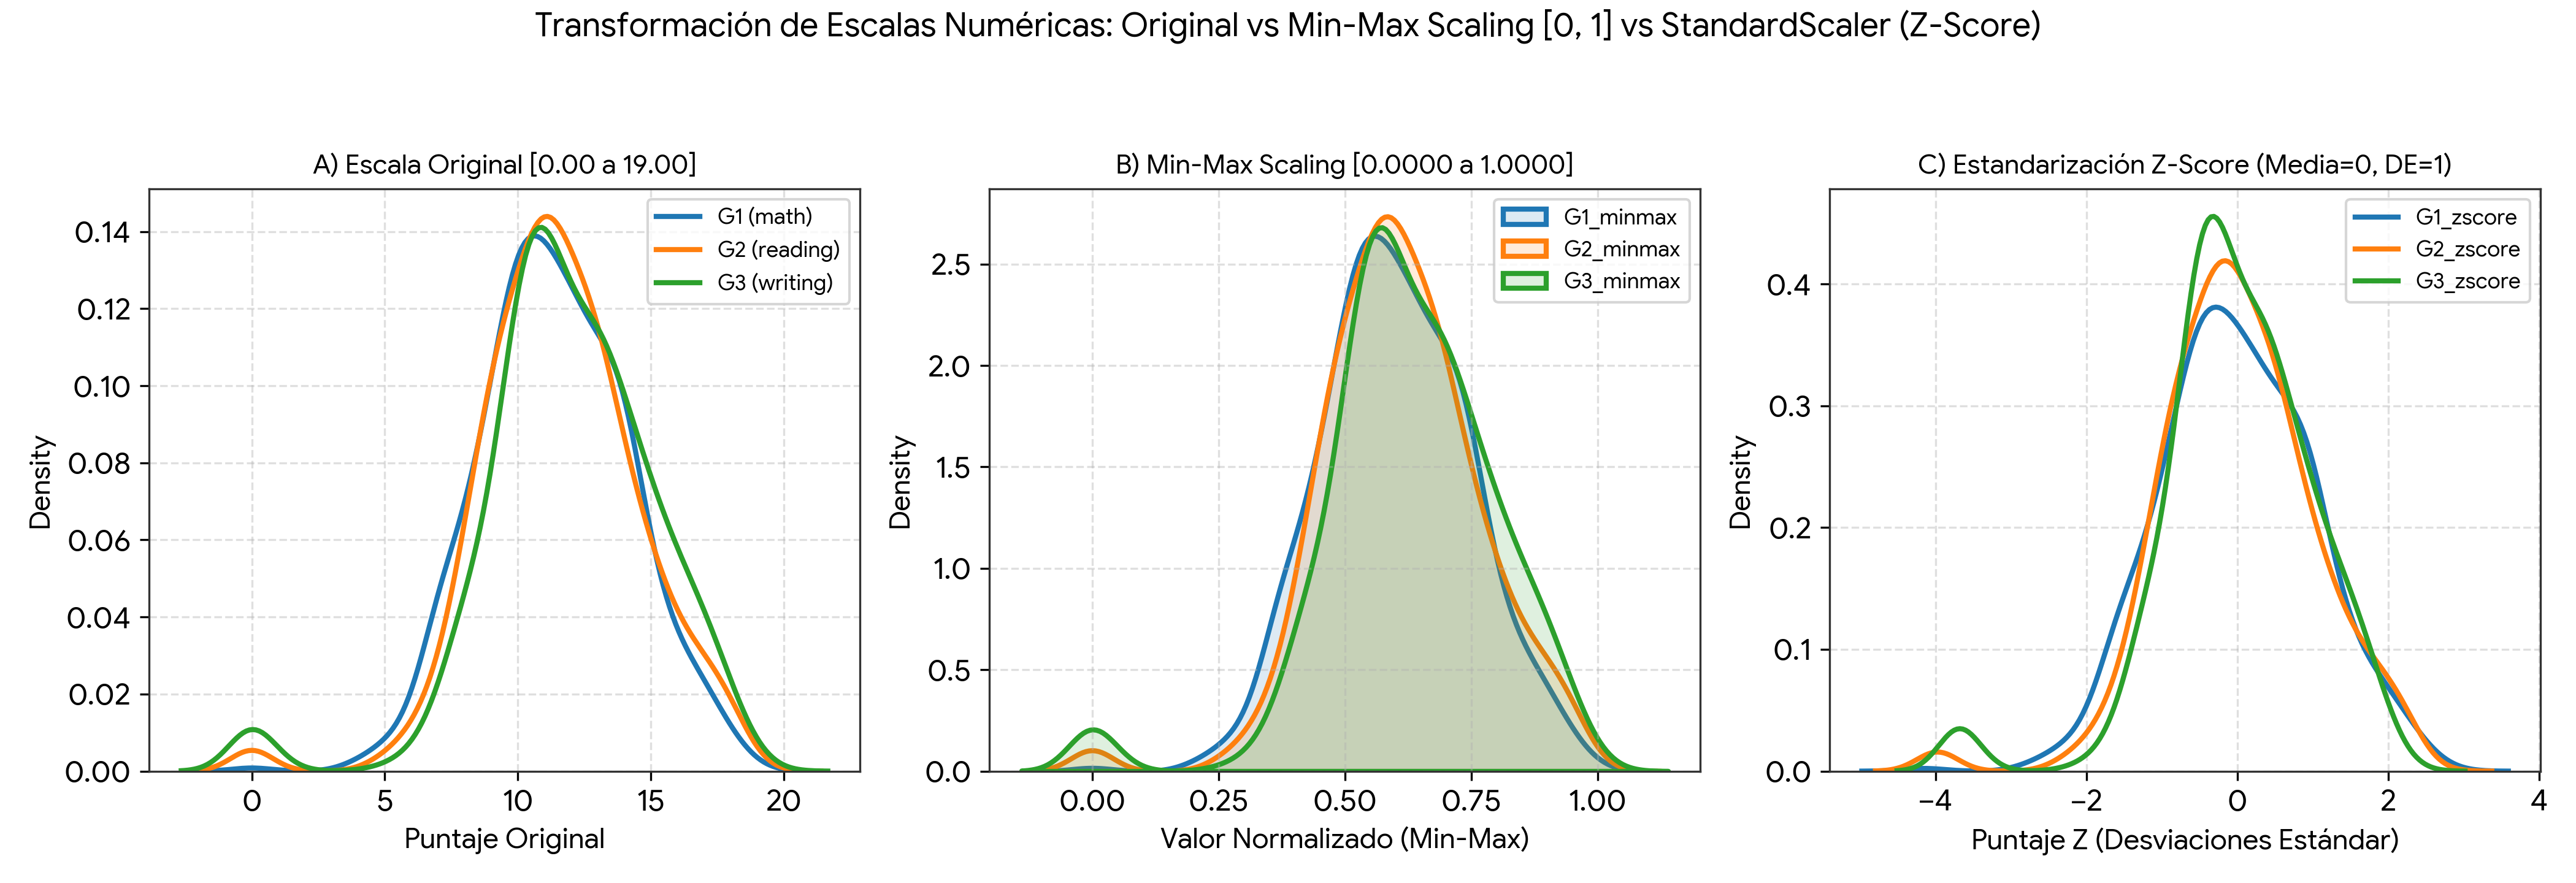

In [4]:
score_cols = ['math_score', 'reading_score', 'writing_score']
scaler_mm = MinMaxScaler(feature_range=(0, 1))
df[['math_minmax', 'reading_minmax', 'writing_minmax']] = scaler_mm.fit_transform(df[score_cols])

scaler_std = StandardScaler()
df[['math_zscore', 'reading_zscore', 'writing_zscore']] = scaler_std.fit_transform(df[score_cols])

print("Resumen estadístico de puntajes normalizados con Min-Max Scaling [0, 1]:")
print(df[['math_minmax', 'reading_minmax', 'writing_minmax']].describe().round(4))


## Pregunta 5: Detección y Manejo de Valores Atípicos (Outliers)
* **Detección con Boxplot e IQR:** En `math_score` (`G1`) existen **16 valores atípicos** fuera del intervalo $[5.5, 17.5]$ ($Q_1 = 10, Q_3 = 13, \text{IQR} = 3$): 8 inferiores ($0, 4, 5$) y 8 superiores ($18, 19$). En `reading_score` (`G2`) existen **25 atípicos** y en `writing_score` (`G3`) existen **16 atípicos** inferiores ($0$ y $1$).
* **Tratamiento:** Como son calificaciones reales dentro de la escala $[0, 20]$ y no errores de captura, se conservan etiquetados para no perder señal sobre deserción/excelencia y se aplica **Winsorización (Capping IQR)** mediante `clip()` para estabilizar modelos paramétricos.


math_score      | Q1=10.0, Q3=13.0, IQR=3.0 | Límites=[5.5, 17.5] | Outliers=16 -> [ 0 18 18 18 18 18  5  4  4  5 18  5  5 18 19  5]
reading_score   | Q1=10.0, Q3=13.0, IQR=3.0 | Límites=[5.5, 17.5] | Outliers=25 -> [18 18 18 18 19 18 18 18 18 18  0  5 18  0  0  5 18 18  0  0  0 18  0  5 18]
writing_score   | Q1=10.0, Q3=14.0, IQR=4.0 | Límites=[4.0, 20.0] | Outliers=16 -> [0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
absences        | Q1=0.0, Q3=6.0, IQR=6.0 | Límites=[-9.0, 15.0] | Outliers=21 -> [16 16 24 22 16 32 16 16 30 21 16 18 16 26 16 16 22 18 18 16 21]


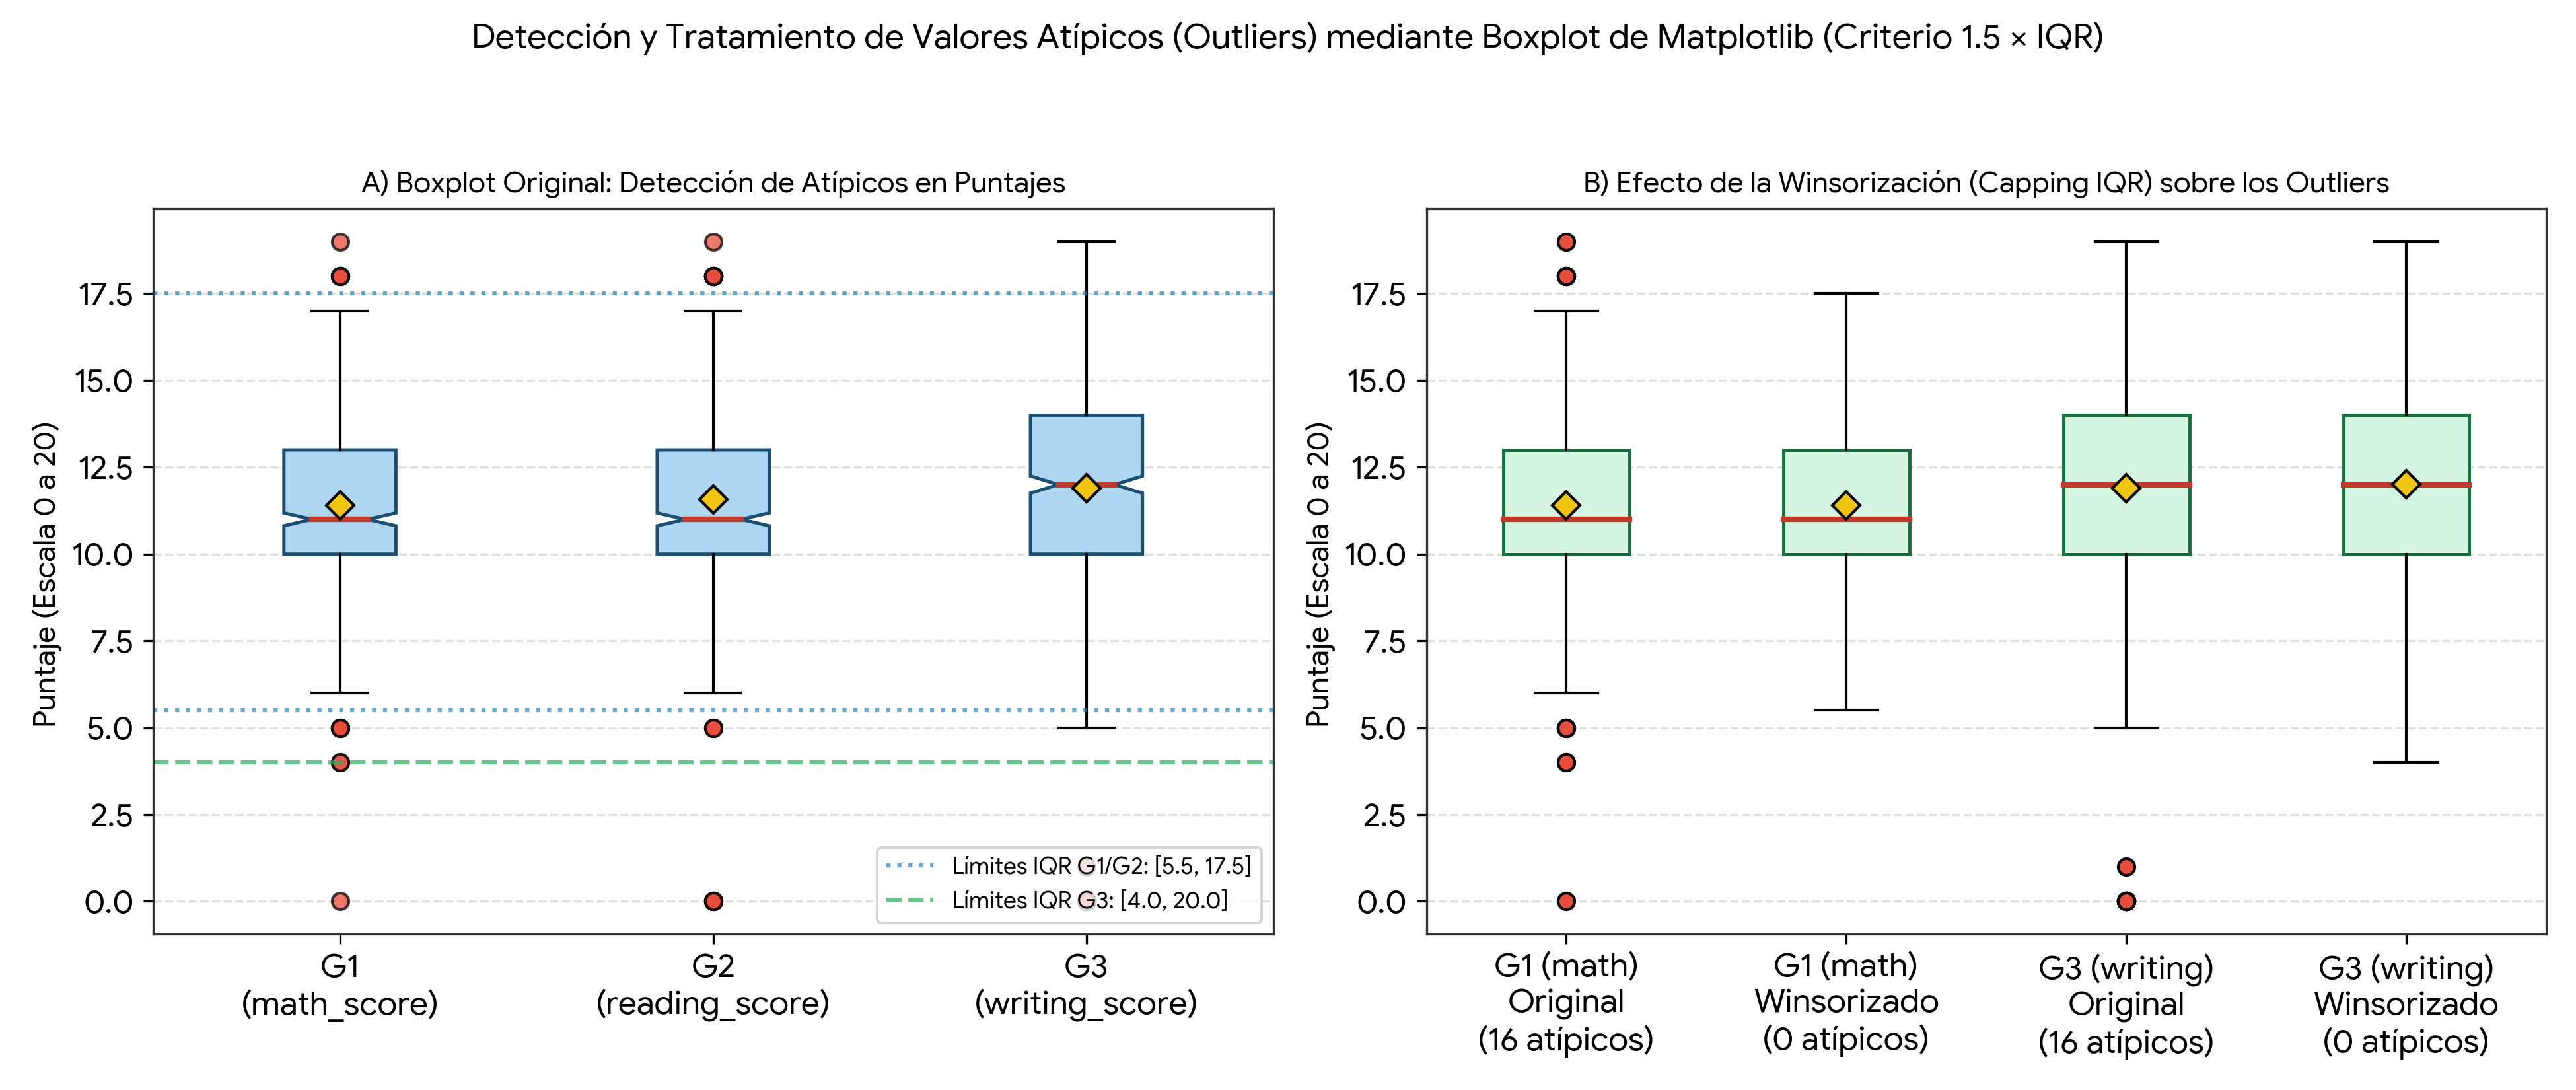

In [5]:
for col in ['math_score', 'reading_score', 'writing_score', 'absences']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < low) | (df[col] > high)][col]
    df[f'{col}_winsor'] = df[col].clip(lower=low, upper=high)
    print(f"{col:<15} | Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f} | Límites=[{low:.1f}, {high:.1f}] | Outliers={len(outliers)} -> {outliers.values}")


## Pregunta 6: Integración de Datasets usando Pandas
Protocolo de 5 pasos con `pd.merge(..., how='left', validate='one_to_one', indicator=True)` para garantizar **cero pérdida de registros** de los 649 estudiantes.


In [6]:
df['student_id'] = [f"STU-{i:04d}" for i in range(1, len(df) + 1)]
np.random.seed(42)
df_socio = pd.DataFrame({
    'student_id': df['student_id'].sample(frac=0.98, random_state=42),
    'ingreso_familiar_clp': np.random.normal(850000, 220000, size=int(len(df)*0.98)).round(0),
    'quintil_socioeconomico': np.random.choice([1, 2, 3, 4, 5], size=int(len(df)*0.98)),
    'beca_alimentacion': np.random.choice(['free/reduced', 'standard'], size=int(len(df)*0.98))
}).drop_duplicates(subset=['student_id'])

df_integrado = pd.merge(df, df_socio, on='student_id', how='left', validate='one_to_one', indicator=True)
print("Auditoría del cruce (_merge):\n", df_integrado['_merge'].value_counts())

df_integrado['ingreso_familiar_clp'] = df_integrado['ingreso_familiar_clp'].fillna(df_integrado['ingreso_familiar_clp'].median())
df_integrado['quintil_socioeconomico'] = df_integrado['quintil_socioeconomico'].fillna(df_integrado['quintil_socioeconomico'].mode()[0])
df_integrado['beca_alimentacion'] = df_integrado['beca_alimentacion'].fillna('standard')

assert len(df_integrado) == len(df), "Error: pérdida de filas detectada"
print(f"\nIntegración completada sin pérdida de datos: {df_integrado.shape[0]} filas conservadas.")


Auditoría del cruce (_merge):
_merge
both          636
left_only      13
right_only      0
Name: count, dtype: int64

Integración completada sin pérdida de datos: 649 filas conservadas.


## Pregunta 7: Análisis de Componentes Principales (PCA) y Selección de Características (Feature Importance)
* **PCA sobre los 3 puntajes de exámenes (`G1`, `G2`, `G3`):** `PC1` captura el **91.35%** de la varianza total ($\lambda_1 = 2.7447$), sintetizando las tres pruebas en un único índice latente de rendimiento.
* **PCA sobre las 16 variables numéricas:** Los primeros 6 componentes superan el Criterio de Kaiser ($\lambda \ge 1.0$, explicando el **65.72%**), y los primeros 9 a 11 componentes retienen entre el **81.92%** y **90.73%** de la varianza total.
* **Feature Importance (Random Forest):** Evalúa no linealmente la importancia predictiva de cada variable sobre `G3`.


PCA (3 puntajes) - Varianza explicada (%): [91.35  6.1   2.55]

Resumen PCA (16 variables numéricas):
      Autovalor (Eigenvalue)  Varianza (%)  Varianza Acumulada (%)
PC1                   3.6709         22.91                   22.91
PC2                   1.9508         12.17                   35.08
PC3                   1.4339          8.95                   44.03
PC4                   1.3240          8.26                   52.29
PC5                   1.1393          7.11                   59.40
PC6                   1.0122          6.32                   65.72
PC7                   0.9263          5.78                   71.50
PC8                   0.8616          5.38                   76.88
PC9                   0.8091          5.05                   81.92
PC10                  0.7818          4.88                   86.80
PC11                  0.6299          3.93                   90.73

Top 10 Feature Importance (%) para predecir G3 (sin notas previas):
failures      19.40
absen

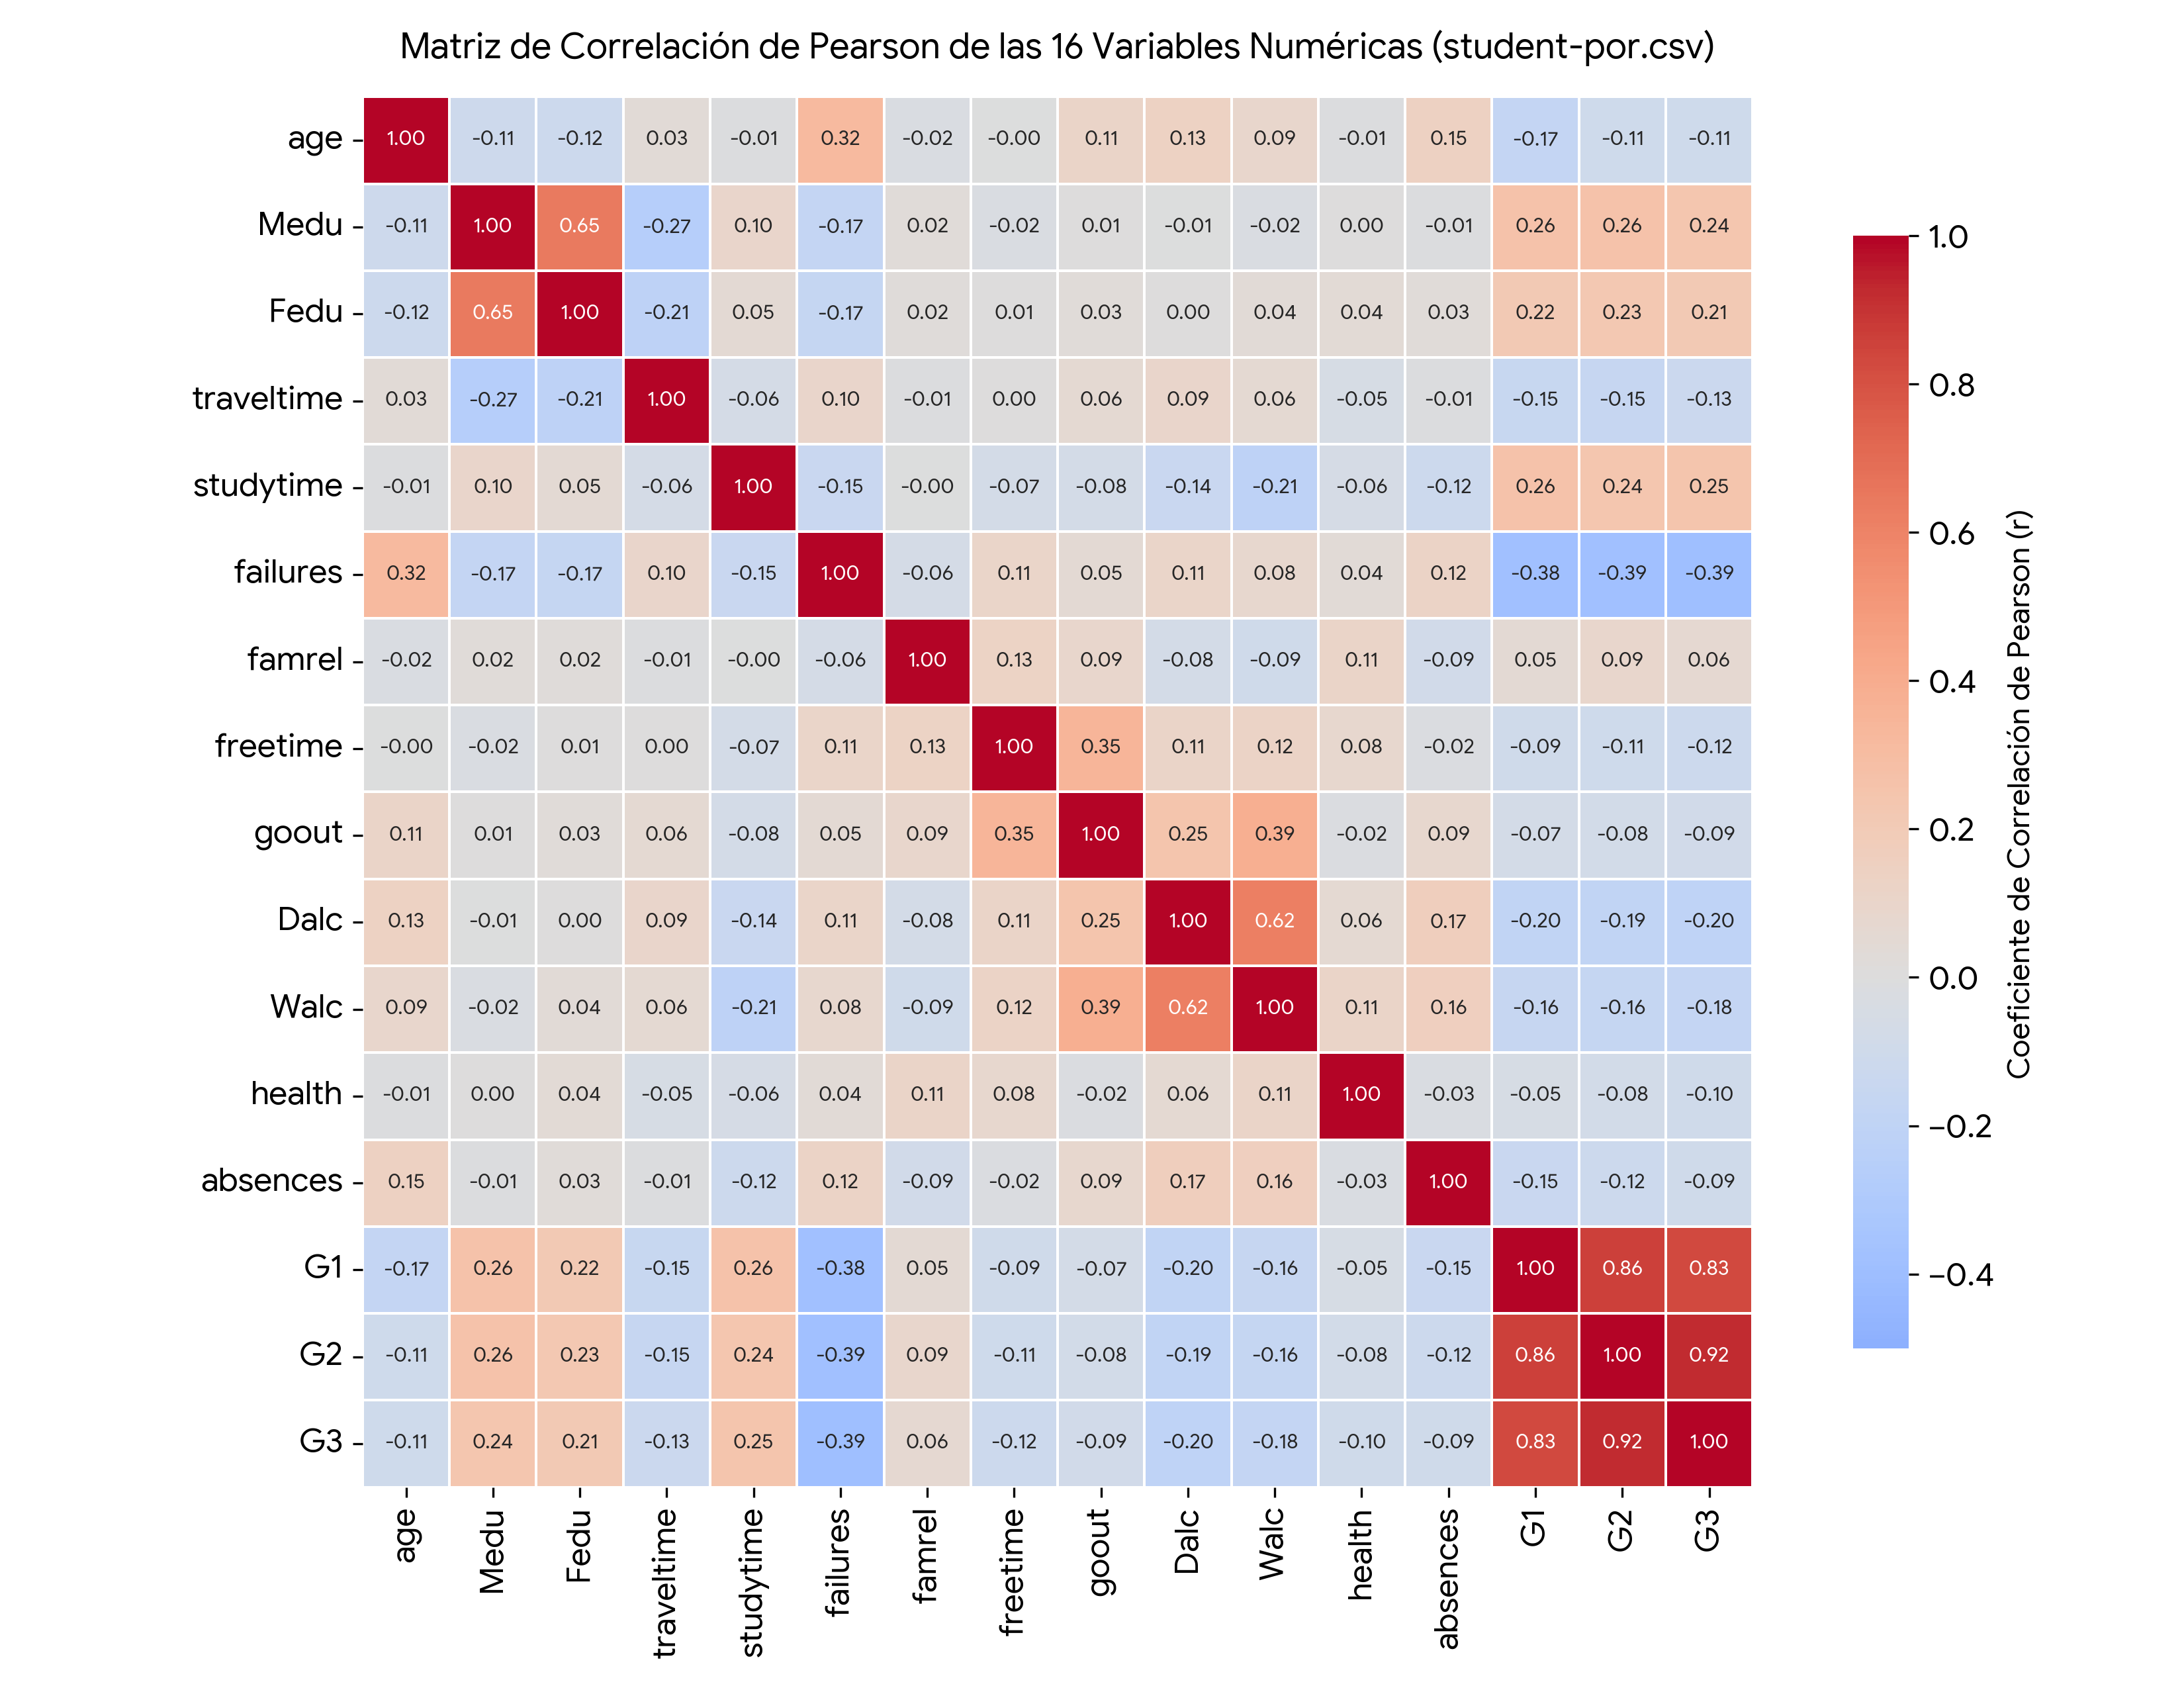

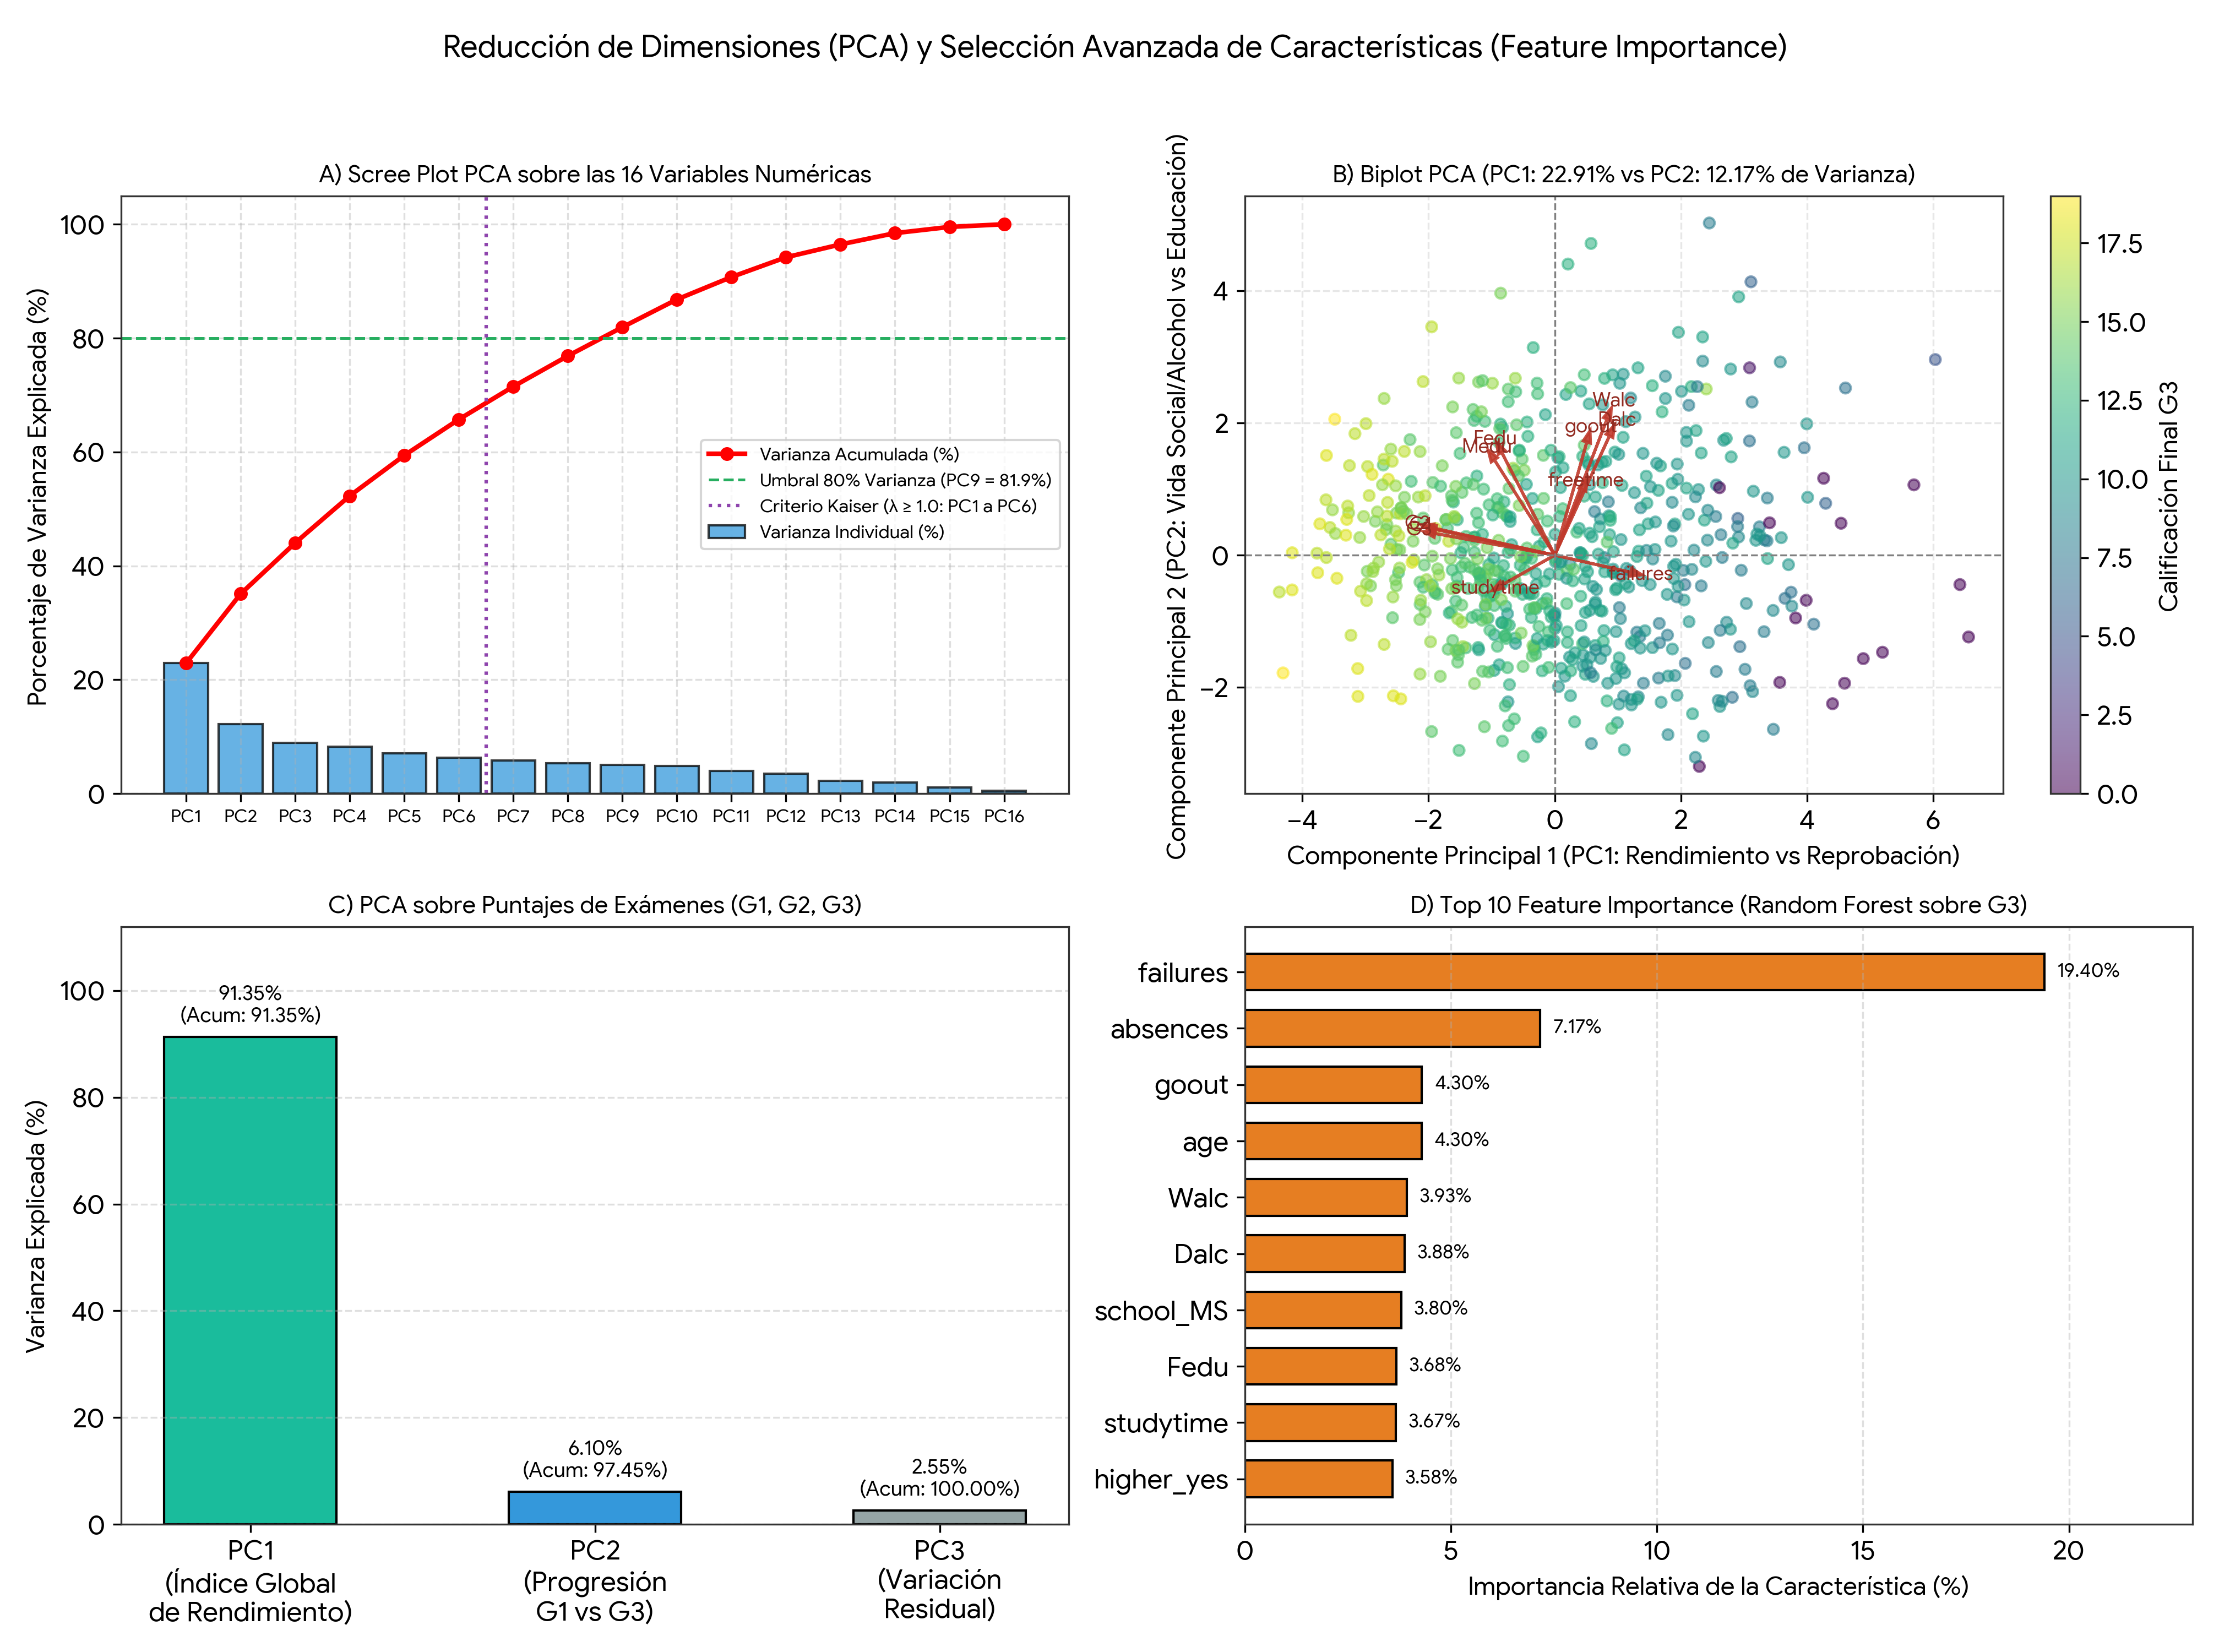

In [7]:
# A) PCA sobre los 3 puntajes de evaluación
X_scores_std = StandardScaler().fit_transform(df[['G1', 'G2', 'G3']])
pca_scores = PCA().fit(X_scores_std)
print("PCA (3 puntajes) - Varianza explicada (%):", (pca_scores.explained_variance_ratio_ * 100).round(2))

# B) PCA sobre las 16 variables numéricas
X_all_std = StandardScaler().fit_transform(df[num_cols])
pca_all = PCA().fit(X_all_std)
pca_summary = pd.DataFrame({
    'Autovalor (Eigenvalue)': pca_all.explained_variance_.round(4),
    'Varianza (%)': (pca_all.explained_variance_ratio_ * 100).round(2),
    'Varianza Acumulada (%)': (np.cumsum(pca_all.explained_variance_ratio_) * 100).round(2)
}, index=[f'PC{i+1}' for i in range(len(num_cols))])
print("\nResumen PCA (16 variables numéricas):")
print(pca_summary.head(11))

# C) Selección de Características con Random Forest Feature Importance
X_rf = pd.get_dummies(df.drop(columns=['G1', 'G2', 'G3', 'gender', 'math_score', 'reading_score',
                                       'writing_score', 'gender_encoded', 'categoria_rendimiento',
                                       'math_minmax', 'reading_minmax', 'writing_minmax',
                                       'math_zscore', 'reading_zscore', 'writing_zscore',
                                       'math_score_winsor', 'reading_score_winsor', 'writing_score_winsor',
                                       'absences_winsor', 'student_id']), drop_first=True)
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_rf, df['G3'])
imp = pd.Series(rf.feature_importances_ * 100, index=X_rf.columns).sort_values(ascending=False)
print("\nTop 10 Feature Importance (%) para predecir G3 (sin notas previas):")
print(imp.head(10).round(2))
